# Preface: Algorithm for Image Denoising Using 2D FFT

This notebook demonstrates an algorithm for denoising images using the 2D Fast Fourier Transform (FFT):

1. **Image Loading:** The noisy image is loaded into a 2D array.
2. **2D FFT:** The 2D FFT is computed to transform the image from the spatial domain to the frequency domain.
3. **Frequency Filtering:** High-frequency components (often corresponding to noise) are attenuated or removed by applying a mask or threshold in the frequency domain.
4. **Inverse 2D FFT:** The filtered frequency data is transformed back to the spatial domain using the inverse FFT, reconstructing a denoised image.
5. **Visualization:** The original, noisy, and denoised images are displayed for comparison, illustrating the effectiveness of frequency-domain filtering.

This approach leverages the fact that noise is typically represented by high-frequency components, while important image features are often contained in lower frequencies.

In [2]:

from matplotlib.image import imread
import numpy as np
import matplotlib.pyplot as plt
import os
plt.rcParams['figure.figsize'] = [16, 16]
plt.rcParams.update({'font.size': 18})

A = imread(os.path.join('..','DATA','dog.jpg'))
B = np.mean(A, -1); # Convert RGB to grayscale


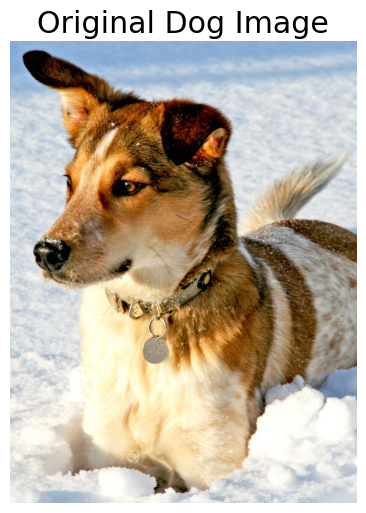

In [3]:
# Display the original dog image
plt.figure(figsize=(6,6))
plt.imshow(A)
plt.axis('off')
plt.title('Original Dog Image')
plt.show()

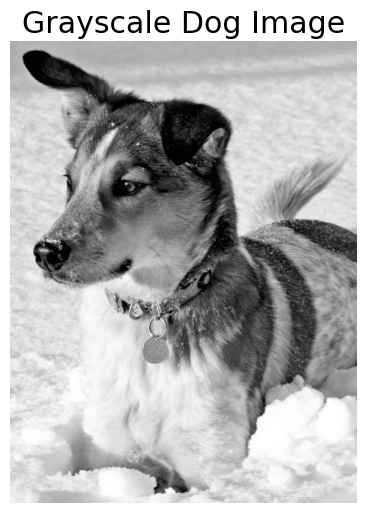

In [5]:
# Display the grayscale dog image
plt.figure(figsize=(6,6))
plt.imshow(B, cmap='gray')
plt.axis('off')
plt.title('Grayscale Dog Image')
plt.show()

### Why use `fftshift`?

The output of the 2D FFT places the zero-frequency (DC) component at the corners of the spectrum array. For visualization and filtering, it's much more intuitive to have the zero-frequency component at the center. The `fftshift` function rearranges the output so that low frequencies are centered and high frequencies are at the edges, making it easier to design frequency filters and interpret the spectrum visually.

### What do negative frequencies mean in the FFT?

In the FFT output, frequencies are represented as both positive and negative values. This is a mathematical consequence of the Fourier transform, which decomposes a real signal into a sum of complex exponentials (sines and cosines) with both positive and negative frequencies.

- **Physical meaning:** For real-valued signals (like images), negative frequencies do not correspond to physically different oscillations—they are a mathematical artifact. The information in negative frequencies is redundant with the positive frequencies.
- **Why keep them?** The full spectrum (positive and negative) is needed for correct reconstruction of the original signal, especially for complex-valued data.
- **Visualization:** After `fftshift`, the spectrum is centered at zero, with negative frequencies on the left and positive on the right. For real images, the spectrum is symmetric about zero.

In summary: negative frequencies are a mathematical tool that, together with positive frequencies, allow the FFT to represent all possible oscillations in a signal.

### Are negative frequencies the complex conjugates of positive frequencies?

Yes, for real-valued signals (like images), the negative frequency components in the FFT are the complex conjugates of the positive frequency components. This property is called Hermitian symmetry:

$$
F(-f) = F^*(f)
$$

where $F(f)$ is the Fourier transform at frequency $f$, and $F^*(f)$ is its complex conjugate. This symmetry ensures that the inverse FFT reconstructs a real signal. For real images, the magnitude spectrum is symmetric about zero frequency, and the phase spectrum is antisymmetric.

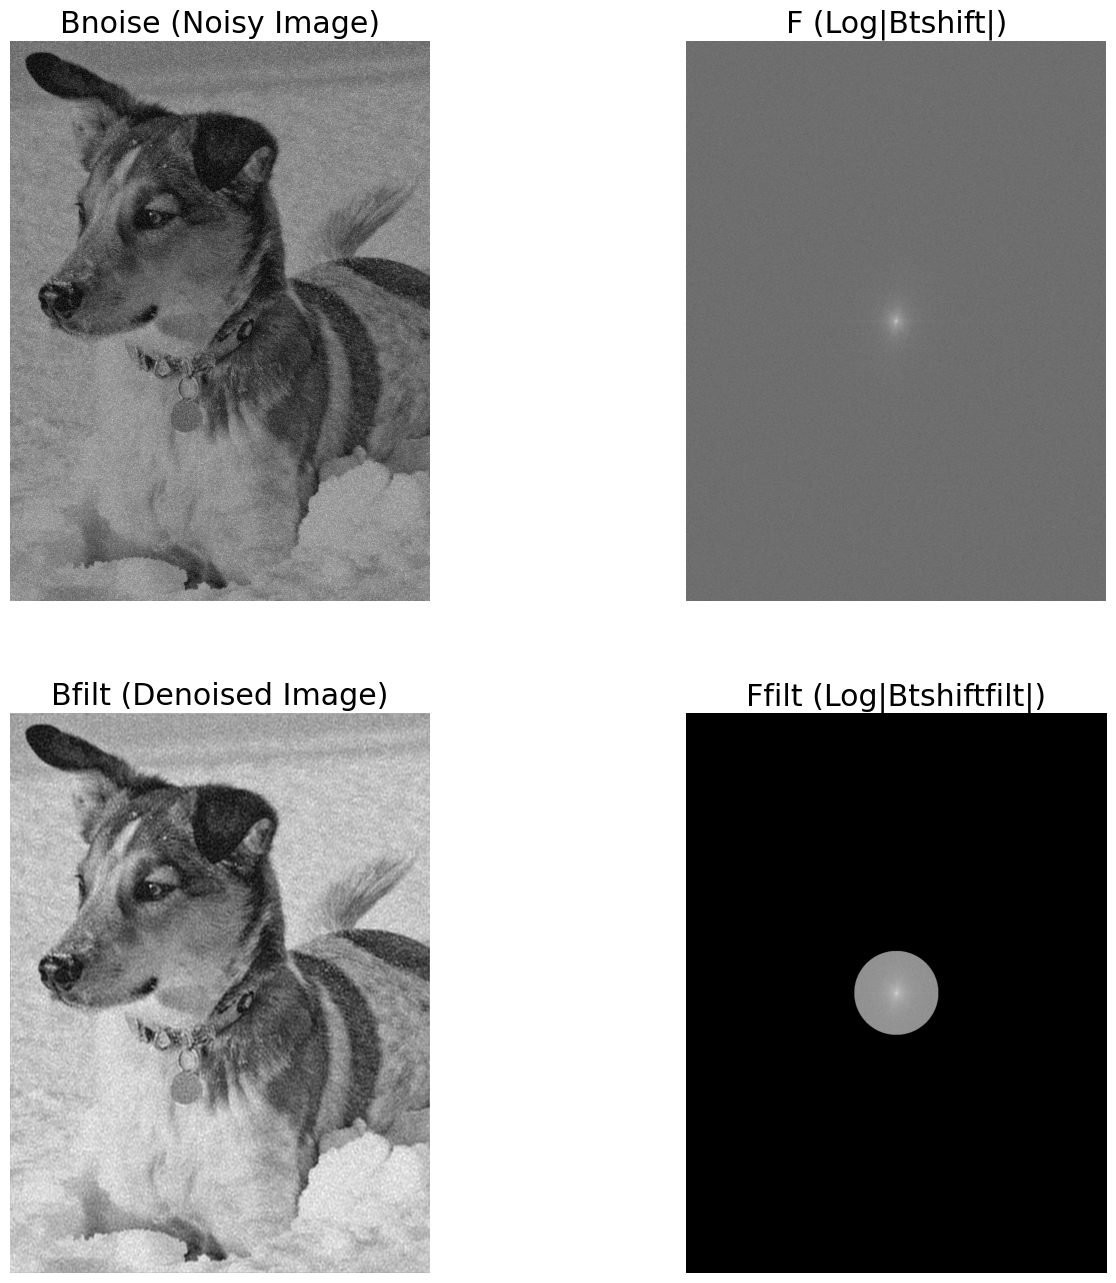

In [10]:
## Denoise
Bnoise = B + 200*np.random.randn(*B.shape).astype('uint8') # Add some noise
Bt = np.fft.fft2(Bnoise)
Btshift = np.fft.fftshift(Bt)
F = np.log(np.abs(Btshift)+1) # Put FFT on log scale

fig,axs = plt.subplots(2,2)

axs[0,0].imshow(Bnoise,cmap='gray')
axs[0,0].axis('off')
axs[0,0].set_title('Bnoise (Noisy Image)')

axs[0,1].imshow(F,cmap='gray')
axs[0,1].axis('off')
axs[0,1].set_title('F (Log|Btshift|)')

nx,ny = B.shape
X,Y = np.meshgrid(np.arange(-ny/2+1,ny/2+1),np.arange(-nx/2+1,nx/2+1))
# xgrid = np.fft.ifftshift(np.arange(-nx/2+1,nx/2+1))
# ygrid = np.fft.ifftshift(np.arange(-ny/2+1,ny/2+1))
# X,Y = np.meshgrid(ygrid,xgrid)
R2 = np.power(X,2) + np.power(Y,2)
ind = R2 < 150**2
Btshiftfilt = Btshift * ind
Ffilt = np.log(np.abs(Btshiftfilt)+1) # Put FFT on log scale

axs[1,1].imshow(Ffilt,cmap='gray')
axs[1,1].axis('off')
axs[1,1].set_title('Ffilt (Log|Btshiftfilt|)')

Btfilt = np.fft.ifftshift(Btshiftfilt)
Bfilt = np.fft.ifft2(Btfilt).real
axs[1,0].imshow(Bfilt,cmap='gray')
axs[1,0].axis('off')
axs[1,0].set_title('Bfilt (Denoised Image)')

plt.show()

In [9]:
# Print all key matrices, their shapes, and descriptions
matrices = [
    (A, 'A', 'Original RGB image (height, width, 3)'),
    (B, 'B', 'Grayscale image (height, width)'),
    (Bnoise, 'Bnoise', 'Noisy grayscale image (height, width)'),
    (Bt, 'Bt', '2D FFT of noisy image (complex, height, width)'),
    (Btshift, 'Btshift', 'Shifted FFT (zero frequency centered)'),
    (F, 'F', 'Log-magnitude spectrum of shifted FFT'),
    (Btshiftfilt, 'Btshiftfilt', 'Filtered FFT (high frequencies removed)'),
    (Ffilt, 'Ffilt', 'Log-magnitude spectrum of filtered FFT'),
    (Btfilt, 'Btfilt', 'Inverse-shifted filtered FFT'),
    (Bfilt, 'Bfilt', 'Denoised image (inverse FFT, real part)')
]

for arr, name, desc in matrices:
    print(f"{name}: shape={arr.shape}, dtype={arr.dtype} -- {desc}")

A: shape=(2000, 1500, 3), dtype=uint8 -- Original RGB image (height, width, 3)
B: shape=(2000, 1500), dtype=float64 -- Grayscale image (height, width)
Bnoise: shape=(2000, 1500), dtype=float64 -- Noisy grayscale image (height, width)
Bt: shape=(2000, 1500), dtype=complex128 -- 2D FFT of noisy image (complex, height, width)
Btshift: shape=(2000, 1500), dtype=complex128 -- Shifted FFT (zero frequency centered)
F: shape=(2000, 1500), dtype=float64 -- Log-magnitude spectrum of shifted FFT
Btshiftfilt: shape=(2000, 1500), dtype=complex128 -- Filtered FFT (high frequencies removed)
Ffilt: shape=(2000, 1500), dtype=float64 -- Log-magnitude spectrum of filtered FFT
Btfilt: shape=(2000, 1500), dtype=complex128 -- Inverse-shifted filtered FFT
Bfilt: shape=(2000, 1500), dtype=float64 -- Denoised image (inverse FFT, real part)
